# Module 8 — Regression Discontinuity Design

Part of the Causal Inference Playbook. Course program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The question: does being allowed to buy alcohol raise the death rate of young Americans?
- The problem: people who drink differ from people who don't in many ways, so comparing the two groups mixes the effect of drinking with those other differences. Comparing older people with younger people mixes the effect of being allowed to buy alcohol with the effect of age.
- The way around: in the US, a person may buy alcohol from their 21st birthday. That age is the cutoff: the value at which a rule switches on for everyone. A person just before the cutoff and a person just after the cutoff are almost the same age. The main thing that changes between the two people is the legal right to buy alcohol. If nothing else that affects the death rate changes at the cutoff, a sudden change in the death rate exactly at the cutoff measures the effect of that right.
- How this module differs from the earlier modules: here nobody is split into a group with the rule and a group without the rule. Everyone gets the right to buy alcohol, at the same age, so the comparison is between ages just before and just after the cutoff.
- The method: regression discontinuity design (RDD). RDD fits a regression line on each side of the cutoff and measures the gap between the two lines at the cutoff. "Discontinuity" means a break in a line.
- The rule RDD needs, the no-other-change rule: nothing else that affects the death rate may change at the cutoff. The data can check the no-other-change rule only in part.

## From the curriculum

> ## <u>Module 8 — Regression Discontinuity Design</u>
>
> **Concepts**
> - Cutoff: the value of a column at which a rule switches on for everyone.
>   Here, the column is age and the cutoff is 21, the minimum legal drinking age
>   in the US.
> - RDD (regression discontinuity design): a regression line on each side of the
>   cutoff. The jump = (line above the cutoff) − (line below the cutoff), both
>   read at the cutoff. The jump is the effect of the rule.
> - The no-other-change rule: nothing else that affects the outcome may change at
>   the cutoff. The data can look for other changes, but can't prove this rule.
> - Bandwidth: how far from the cutoff the data reaches. A narrower bandwidth
>   relies less on straight lines, and usually gives a wider confidence interval.
> - Fake cutoffs: the same calculation at a value where no rule changes. A jump
>   there that chance can't explain would mean the method finds jumps that
>   aren't real.
> - The density check: when people can choose their side of a cutoff, count the
>   people just below and just above the cutoff. "Density" means how many people
>   sit at each value. Many more people on one side than on the other shows that
>   people chose.
>
> **Why it matters**
> Many rules switch on at a threshold: an age, a test score, an order size.
> People just below and just above a threshold are alike, so a gap in the
> outcome at the threshold comes from the rule. The price: the jump describes
> only people near the cutoff, and the no-other-change rule can't be proved.
>
> **Worked example**
> US death rates by age, from 19 to 23, from a 2009 study by Christopher
> Carpenter and Carlos Dobkin. The jump in deaths at 21, the jump's 95% confidence
> interval, three bandwidths, fake cutoffs at 20 and 22, and deaths from disease
> against deaths from outside causes.
>
> **Resources**
> - [Causal Inference: The Mixtape, ch. 6 "Regression Discontinuity"](https://mixtape.scunning.com/06-regression_discontinuity)
>   (Scott Cunningham, ~90 min, verified): the method's rules (6.2), estimation
>   and bandwidths (6.3), and the density check (6.4).
> - [The Effect, ch. 20 "Regression Discontinuity"](https://theeffectbook.net/ch-RegressionDiscontinuity.html)
>   (Nick Huntington-Klein, ~60 min, verified): RDD with a regression (20.2.1),
>   fake cutoffs (20.2.3), the density check (20.2.4), and bandwidths (20.3.4).
> - [A/B Testing Playbook, Module 8, Part 4](https://github.com/omri-sabag83/A-B-Testing-Playbook/blob/main/08_quasi_experiments.ipynb):
>   a short version of the same idea on made-up data.
>
> **Exercise type:** the jump at 21 in deaths from motor vehicle accidents.
> Fully worked.
>
> **Interview angle:** "Orders of $50 or more get free shipping. Did free
> shipping make customers order again?"

## The data

US death rates by age, from death records used in a 2009 study by Christopher Carpenter and Carlos Dobkin. Each row is one age group, 30 days wide, between the ages of 19 and 23. This section uses two of the file's columns:
- Age: the file gives one age per group, in years. Each age is the middle of its 30-day group, so the first group after a birthday sits 15 days in: 21 + (15 ÷ 365) = 21.0411. Neighbouring age groups are 30 days apart.
- Death rate: deaths from all causes per 100,000 people per year. A death rate of 93 means that, out of 100,000 people of that age, 93 die within a year.

Two rows of the file have no death rate, so the module drops those two rows.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import common

raw = pd.read_stata(common.RAW / "AEJfigs.dta")
empty = raw[raw["all"].isna()]
filled = [name for name in raw.columns if empty[name].notna().all()]
deaths = raw.dropna(subset=["all"]).rename(columns={"agecell": "age", "all": "death_rate"}).reset_index(drop=True)
deaths["age"] = deaths.age.astype(float)
print(f"Rows in the file = {len(raw)}")
print(f"Rows with no death rate = {len(empty)}, at ages {empty.agecell.iloc[0]:.5f} and {empty.agecell.iloc[1]:.5f}")
fitted = [name for name in filled if name.endswith("fitted")]
print(f"  Columns with values in those two rows: the age column, and {len(fitted)} columns whose names end in 'fitted'")
print(f"Age groups used = {len(raw)} - {len(empty)} = {len(deaths)}")
print(f"  Below 21 = {(deaths.age < 21).sum()} age groups, from age {deaths.age.min():.2f} to {deaths[deaths.age < 21].age.max():.2f}")
print(f"  21 or above = {(deaths.age >= 21).sum()} age groups, from age {deaths[deaths.age >= 21].age.min():.2f} to {deaths.age.max():.2f}")

Rows in the file = 50
Rows with no death rate = 2, at ages 20.99999 and 21.00000
  Columns with values in those two rows: the age column, and 9 columns whose names end in 'fitted'
Age groups used = 50 - 2 = 48
  Below 21 = 24 age groups, from age 19.07 to 20.96
  21 or above = 24 age groups, from age 21.04 to 22.93


## Does the death rate change at 21?

Before calculating anything, the chart shows each age group's death rate. If being allowed to buy alcohol raises the death rate, the points just after 21 sit higher than the points just before 21.

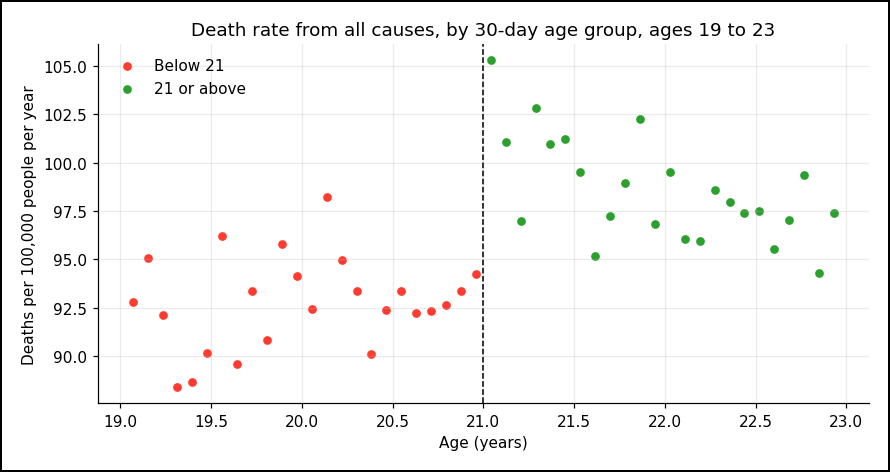

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.2))
below, above = deaths[deaths.age < 21], deaths[deaths.age >= 21]
ax.scatter(below.age, below.death_rate, color="#ff3b30", s=22, label="Below 21")
ax.scatter(above.age, above.death_rate, color="#2ca02c", s=22, label="21 or above")
ax.axvline(21, color="black", ls="--", lw=1)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Deaths per 100,000 people per year")
ax.set_title("Death rate from all causes, by 30-day age group, ages 19 to 23")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Observation:** the green points, at 21 or above, sit higher than the red points just before 21. Inside each side, the points go up and down from one age group to the next.

## How big is the jump at 21?

Comparing only the last age group before 21 with the first age group after 21 would rest on two points, and each point goes up and down by chance, as the chart shows. So RDD fits one straight line through the 24 age groups below 21 and another through the 24 age groups at 21 or above. Each line uses 24 age groups, so one group's chance up or down moves the line only a little.

Each line is a regression of death rate on age:
- Age gap = (group's age) − (mean age). Death-rate gap = (group's death rate) − (mean death rate).
- Slope = [mean of (age gap × death-rate gap)] ÷ [mean of (age gap²)]. In words: the slope is how much the death rate rises, on average, for each extra year of age.
- Error = (group's death rate) − (line's death rate at the group's age).
- The regression picks the line with the smallest sum of squared errors.
- That line passes through the point (mean age, mean death rate), so the line's death rate at 21 = (mean death rate) + [slope × (21 − mean age)].

Then:
- Jump = (line at 21 or above, death rate at 21) − (line below 21, death rate at 21).
- To compare the jump with the death rate just below 21, the output also gives the rise in percent = (jump) ÷ (line below 21, death rate at 21).

Each table lists the 24 age groups of one line, so every mean below can be checked by hand from the table's column sums.

In [3]:
def fit_line(groups, column, cutoff):
    age = groups.age.round(3).reset_index(drop=True)
    rate = groups[column].astype(float).round(2).reset_index(drop=True)
    n = len(groups)
    mean_age, mean_rate = round(age.sum() / n, 3), round(rate.sum() / n, 2)
    age_gap, rate_gap = (age - mean_age).round(3), (rate - mean_rate).round(2)
    product, age_square = (age_gap * rate_gap).round(5), (age_gap ** 2).round(5)
    mean_product, mean_square = round(product.sum() / n, 5), round(age_square.sum() / n, 5)
    slope = round(mean_product / mean_square, 3)
    on_line = (mean_rate + slope * (age - mean_age)).round(2)
    error = (rate - on_line).round(2)
    table = pd.DataFrame({"Age": age.map("{:.3f}".format), "Death rate": rate.map("{:.2f}".format),
                          "Age gap": age_gap.map("{:.3f}".format), "Death-rate gap": rate_gap.map("{:.2f}".format),
                          "Age gap x death-rate gap": product.map("{:.5f}".format), "Age gap²": age_square.map("{:.5f}".format),
                          "Line's death rate": on_line.map("{:.2f}".format), "Error": error.map("{:.2f}".format),
                          "Error²": (error ** 2).round(4).map("{:.4f}".format)})
    return dict(groups=n, cutoff=cutoff, table=table, sum_age=age.sum(), sum_rate=rate.sum(), mean_age=mean_age, mean_rate=mean_rate,
                sum_product=product.sum(), sum_square=age_square.sum(), mean_product=mean_product, mean_square=mean_square, slope=slope,
                at_cutoff=round(mean_rate + slope * (cutoff - mean_age), 2), sum_error=error.sum(), sum_squared=round((error ** 2).round(4).sum(), 2))

def print_fit(line, label, columns):
    n, cutoff = line["groups"], line["cutoff"]
    print(f"{label} ({n} age groups):")
    common.show(line["table"][columns])
    print(f"  Mean age = (sum of ages) / {n} = {line['sum_age']:.3f} / {n} = {line['mean_age']:.3f} years")
    print(f"  Mean death rate = (sum of death rates) / {n} = {line['sum_rate']:.2f} / {n} = {line['mean_rate']:.2f}")
    print(f"  Mean of (age gap x death-rate gap) = (sum of the column) / {n} = {line['sum_product']:.5f} / {n} = {line['mean_product']:.5f}")
    print(f"  Mean of (age gap²) = (sum of the column) / {n} = {line['sum_square']:.5f} / {n} = {line['mean_square']:.5f}")
    print("  Slope")
    print("    = [mean of (age gap x death-rate gap)] / [mean of (age gap²)]")
    print(f"    = {line['mean_product']:.5f} / {line['mean_square']:.5f} = {line['slope']:.3f} per year of age")
    print(f"  Line's death rate at {cutoff}")
    print(f"    = (mean death rate) + [slope x ({cutoff} - mean age)]")
    print(f"    = {line['mean_rate']:.2f} + [{line['slope']:.3f} x ({cutoff} - {line['mean_age']:.3f})] = {line['at_cutoff']:.2f}")
    print()

FIT_COLUMNS = ["Age", "Death rate", "Age gap", "Death-rate gap", "Age gap x death-rate gap", "Age gap²"]
below_line = fit_line(deaths[deaths.age < 21], "death_rate", 21)
print_fit(below_line, "Line below 21, all causes", FIT_COLUMNS)

Line below 21, all causes (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²
19.068       92.83   -0.946            0.03                  -0.02838   0.89492
19.151       95.10   -0.863            2.30                  -1.98490   0.74477
19.233       92.14   -0.781           -0.66                   0.51546   0.60996
19.315       88.43   -0.699           -4.37                   3.05463   0.48860
19.397       88.70   -0.617           -4.10                   2.52970   0.38069
19.479       90.19   -0.535           -2.61                   1.39635   0.28622
19.562       96.22   -0.452            3.42                  -1.54584   0.20430
19.644       89.62   -0.370           -3.18                   1.17660   0.13690
19.726       93.38   -0.288            0.58                  -0.16704   0.08294
19.808       90.86   -0.206           -1.94                   0.39964   0.04244
19.890       95.81   -0.124            3.01                  -0.37324   0.015

In [4]:
above_line = fit_line(deaths[deaths.age >= 21], "death_rate", 21)
print_fit(above_line, "Line at 21 or above, all causes", FIT_COLUMNS)

Line at 21 or above, all causes (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²
21.041      105.27   -0.945            6.73                  -6.35985   0.89302
21.123      101.07   -0.863            2.53                  -2.18339   0.74477
21.205       96.97   -0.781           -1.57                   1.22617   0.60996
21.288      102.83   -0.698            4.29                  -2.99442   0.48720
21.370      100.98   -0.616            2.44                  -1.50304   0.37946
21.452      101.24   -0.534            2.70                  -1.44180   0.28516
21.534       99.50   -0.452            0.96                  -0.43392   0.20430
21.616       95.20   -0.370           -3.34                   1.23580   0.13690
21.699       97.26   -0.287           -1.28                   0.36736   0.08237
21.781       98.93   -0.205            0.39                  -0.07995   0.04202
21.863      102.26   -0.123            3.72                  -0.45756  

In [5]:
jump = round(above_line["at_cutoff"] - below_line["at_cutoff"], 2)
print("Jump at 21, all causes (48 age groups):")
print("  = (line at 21 or above, death rate at 21) - (line below 21, death rate at 21)")
print(f"  = {above_line['at_cutoff']:.2f} - {below_line['at_cutoff']:.2f} = {jump:.2f} deaths per 100,000 people per year")
print()
print("Rise at 21, all causes:")
print("  = (jump) / (line below 21, death rate at 21)")
print(f"  = {jump:.2f} / {below_line['at_cutoff']:.2f} = {jump / below_line['at_cutoff']:.1%}")

Jump at 21, all causes (48 age groups):
  = (line at 21 or above, death rate at 21) - (line below 21, death rate at 21)
  = 101.28 - 93.62 = 7.66 deaths per 100,000 people per year

Rise at 21, all causes:
  = (jump) / (line below 21, death rate at 21)
  = 7.66 / 93.62 = 8.2%


**Observation:** at 21, the death rate jumps by 7.66 deaths per 100,000 people per year, a rise of 8.2%. The two slopes have opposite signs: before 21 the death rate rises by 0.827 per year of age, and from 21 on it falls by 2.778 per year of age. One straight line across both sides would have one slope and would fit neither side, which is why RDD fits a separate line on each side. Both lines have the same mean of (age gap²), 0.32378, because each side has 24 age groups, 30 days apart.

- The data has no column for how much people drink, so the jump measures the effect of being allowed to buy alcohol, not the effect of one drink.
- The jump describes people turning 21. The data can't say what the right to buy alcohol would do at another age.

The chart shows the two lines, dashed, and one straight line through all 48 age groups, in grey.

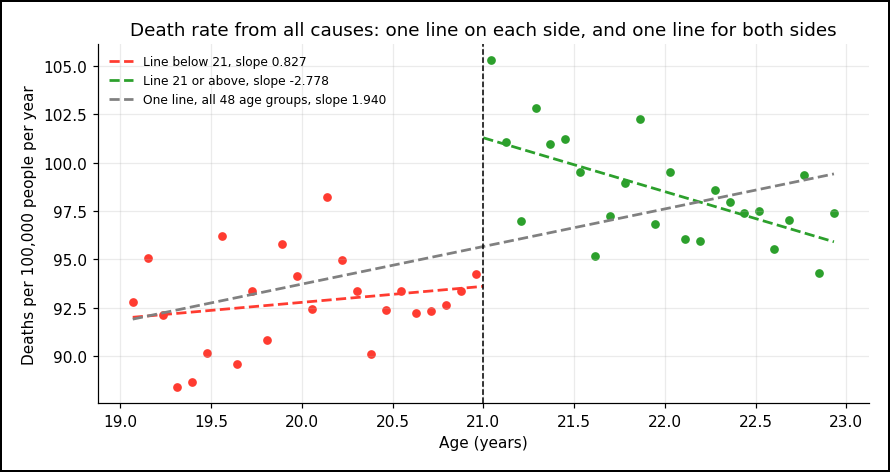

In [6]:
joint_line = fit_line(deaths, "death_rate", 21)
fig, ax = plt.subplots(figsize=(8, 4.2))
for line, groups, color, label in [(below_line, deaths[deaths.age < 21], "#ff3b30", "Below 21"), (above_line, deaths[deaths.age >= 21], "#2ca02c", "21 or above")]:
    ends = [groups.age.min(), 21] if groups.age.max() < 21 else [21, groups.age.max()]
    ax.scatter(groups.age, groups.death_rate, color=color, s=22)
    ax.plot(ends, [line["mean_rate"] + line["slope"] * (end - line["mean_age"]) for end in ends], color=color, ls="--", lw=1.8, label=f"Line {label.lower()}, slope {line['slope']:.3f}")
ends = [deaths.age.min(), deaths.age.max()]
ax.plot(ends, [joint_line["mean_rate"] + joint_line["slope"] * (end - joint_line["mean_age"]) for end in ends], color="grey", ls="--", lw=1.8, label=f"One line, all 48 age groups, slope {joint_line['slope']:.3f}")
ax.axvline(21, color="black", ls="--", lw=1)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Deaths per 100,000 people per year")
ax.set_title("Death rate from all causes: one line on each side, and one line for both sides")
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## Could chance alone produce a jump of 7.66?

The deaths in each age group include chance: had the same people of each age lived through the same years again, a few more/less of those people would have died. So each line's death rate at 21, and the jump, would come out a little different. The 7.66 is therefore an estimate of the true jump. The 95% confidence interval is a range built so that, in 95 of 100 such repeats, the range would contain the true jump. We want 0 outside the interval, because we are looking for an effect: 0 inside the interval would mean that chance alone could produce the jump.

The interval needs each line's errors, because the errors show how far the death rates scatter around each line, and more scatter means a line that moves more by chance. The tables list the errors:

In [7]:
ERROR_COLUMNS = ["Age", "Death rate", "Line's death rate", "Error", "Error²"]

def print_error_table(line, label):
    print(f"{label} (24 age groups):")
    common.show(line["table"][ERROR_COLUMNS])
    print(f"  Sum of errors = {line['sum_error']:.2f}" + (", not exactly 0, because the mean death rate, the slope and each error are rounded" if round(line['sum_error'], 2) != 0 else ""))
    print(f"  Sum of squared errors = (sum of the Error² column) = {line['sum_squared']:.2f}")

print_error_table(below_line, "Line below 21, all causes")

Line below 21, all causes (24 age groups):
   Age  Death rate  Line's death rate  Error   Error²
19.068       92.83              92.02   0.81   0.6561
19.151       95.10              92.09   3.01   9.0601
19.233       92.14              92.15  -0.01   0.0001
19.315       88.43              92.22  -3.79  14.3641
19.397       88.70              92.29  -3.59  12.8881
19.479       90.19              92.36  -2.17   4.7089
19.562       96.22              92.43   3.79  14.3641
19.644       89.62              92.49  -2.87   8.2369
19.726       93.38              92.56   0.82   0.6724
19.808       90.86              92.63  -1.77   3.1329
19.890       95.81              92.70   3.11   9.6721
19.973       94.16              92.77   1.39   1.9321
20.055       92.46              92.83  -0.37   0.1369
20.137       98.25              92.90   5.35  28.6225
20.219       94.96              92.97   1.99   3.9601
20.301       93.39              93.04   0.35   0.1225
20.384       90.12              93.11  

In [8]:
print_error_table(above_line, "Line at 21 or above, all causes")

Line at 21 or above, all causes (24 age groups):
   Age  Death rate  Line's death rate  Error   Error²
21.041      105.27             101.17   4.10  16.8100
21.123      101.07             100.94   0.13   0.0169
21.205       96.97             100.71  -3.74  13.9876
21.288      102.83             100.48   2.35   5.5225
21.370      100.98             100.25   0.73   0.5329
21.452      101.24             100.02   1.22   1.4884
21.534       99.50              99.80  -0.30   0.0900
21.616       95.20              99.57  -4.37  19.0969
21.699       97.26              99.34  -2.08   4.3264
21.781       98.93              99.11  -0.18   0.0324
21.863      102.26              98.88   3.38  11.4244
21.945       96.83              98.65  -1.82   3.3124
22.027       99.50              98.43   1.07   1.1449
22.110       96.07              98.20  -2.13   4.5369
22.192       95.97              97.97  -2.00   4.0000
22.274       98.61              97.74   0.87   0.7569
22.356       97.95              9

From the errors to the standard error of each line's death rate at 21. A standard error is the usual size of the change in a number from one repeat of the years to another.

- The line's height is the line's death rate at the mean age, which is the mean death rate. The line has two numbers, the height and the slope.
- Mean squared error = (sum of squared errors) ÷ (24 age groups − 2). The 2 counts the line's two numbers: the line chose those two numbers to make the errors small, so dividing by all 24 age groups would make the mean too small.
- The line's death rate at 21 can be off for two reasons:
  1. The height can be off. The height is a mean over 24 age groups, and the standard error of a mean = square root of [(mean squared error) ÷ (number of values)].
     - So standard error of the height = square root of [(mean squared error) ÷ 24].
  2. The slope can be off. Standard error of the slope = square root of [(mean squared error) ÷ (sum of squared differences in age)], where sum of squared differences in age = sum of the Age gap² column. A different slope changes the line's death rate at every age except the mean age, by (change in slope) × (distance from the mean age). 21 sits about one year from each line's mean age.
     - So a slope that is off by its standard error moves the line's death rate at 21 by (standard error of the slope) × (distance from the mean age to 21).
- The height's error and the slope's error are unrelated: the height is the plain mean of the death rates, while the slope weighs each death rate by its age gap, and the age gaps add up to 0. So a chance rise in every death rate raises the height and leaves the slope the same.
- When two chance errors are unrelated, sometimes the two errors have the same sign and add, and sometimes opposite signs and partly cancel. So the standard error of their sum is less than the two standard errors added: standard error of the sum = square root of [(first standard error)² + (second standard error)²].
  - So standard error of the line's death rate at 21 = square root of [(mean squared error ÷ 24) + (distance × standard error of the slope)²].
- The two lines use separate age groups, so their chance errors are unrelated too.
  - Standard error of the jump = square root of [(standard error, line below 21)² + (standard error, line at 21 or above)²].
- 95% confidence interval = (jump) ± (1.96 × standard error of the jump). The 1.96 is the standard multiplier for a 95% range.

In [9]:
def line_error(line):
    n, cutoff = line["groups"], line["cutoff"]
    mean_squared = round(line["sum_squared"] / (n - 2), 3)
    squared_differences = round(line["sum_square"], 5)
    slope_se = round((mean_squared / squared_differences) ** 0.5, 3)
    distance = round(abs(cutoff - line["mean_age"]), 3)
    at_cutoff_se = round((mean_squared / n + (distance * slope_se) ** 2) ** 0.5, 3)
    return dict(mean_squared=mean_squared, squared_differences=squared_differences, slope_se=slope_se, distance=distance, at_cutoff_se=at_cutoff_se)

def print_error(line, error, label):
    n, cutoff = line["groups"], line["cutoff"]
    far, near = (cutoff, line["mean_age"]) if line["mean_age"] < cutoff else (line["mean_age"], cutoff)
    print(f"{label} ({n} age groups):")
    print("  Mean squared error")
    print(f"    = (sum of squared errors) / ({n} age groups - 2)")
    print(f"    = {line['sum_squared']:.2f} / {n - 2} = {error['mean_squared']:.3f}")
    print(f"  Sum of squared differences in age = (sum of the Age gap² column) = {error['squared_differences']:.5f}")
    print("  Standard error of the slope")
    print("    = square root of [(mean squared error) / (sum of squared differences in age)]")
    print(f"    = square root of ({error['mean_squared']:.3f} / {error['squared_differences']:.5f}) = {error['slope_se']:.3f}")
    fmt = lambda v: f"{v:.3f}" if v != int(v) else f"{v:g}"
    print(f"  Distance from the mean age to {cutoff} = {fmt(far)} - {fmt(near)} = {error['distance']:.3f} years")
    print(f"  Standard error of the line's death rate at {cutoff}")
    print(f"    = square root of [(mean squared error / {n}) + (distance x standard error of the slope)²]")
    print(f"    = square root of [({error['mean_squared']:.3f} / {n}) + ({error['distance']:.3f} x {error['slope_se']:.3f})²] = {error['at_cutoff_se']:.3f}")
    print()

below_error = line_error(below_line)
print_error(below_line, below_error, "Line below 21, all causes")

Line below 21, all causes (24 age groups):
  Mean squared error
    = (sum of squared errors) / (24 age groups - 2)
    = 125.43 / 22 = 5.701
  Sum of squared differences in age = (sum of the Age gap² column) = 7.77077
  Standard error of the slope
    = square root of [(mean squared error) / (sum of squared differences in age)]
    = square root of (5.701 / 7.77077) = 0.857
  Distance from the mean age to 21 = 21 - 20.014 = 0.986 years
  Standard error of the line's death rate at 21
    = square root of [(mean squared error / 24) + (distance x standard error of the slope)²]
    = square root of [(5.701 / 24) + (0.986 x 0.857)²] = 0.975



In [10]:
above_error = line_error(above_line)
print_error(above_line, above_error, "Line at 21 or above, all causes")

Line at 21 or above, all causes (24 age groups):
  Mean squared error
    = (sum of squared errors) / (24 age groups - 2)
    = 103.82 / 22 = 4.719
  Sum of squared differences in age = (sum of the Age gap² column) = 7.77077
  Standard error of the slope
    = square root of [(mean squared error) / (sum of squared differences in age)]
    = square root of (4.719 / 7.77077) = 0.779
  Distance from the mean age to 21 = 21.986 - 21 = 0.986 years
  Standard error of the line's death rate at 21
    = square root of [(mean squared error / 24) + (distance x standard error of the slope)²]
    = square root of [(4.719 / 24) + (0.986 x 0.779)²] = 0.887



In [11]:
jump_se = round((below_error["at_cutoff_se"] ** 2 + above_error["at_cutoff_se"] ** 2) ** 0.5, 2)
low, high = round(jump - 1.96 * jump_se, 2), round(jump + 1.96 * jump_se, 2)
print("Standard error of the jump, all causes:")
print("  = square root of [(standard error, line below 21)² + (standard error, line at 21 or above)²]")
print(f"  = square root of ({below_error['at_cutoff_se']:.3f}² + {above_error['at_cutoff_se']:.3f}²) = {jump_se:.2f}")
print()
print("95% confidence interval of the jump, all causes:")
print("  = (jump) +/- (1.96 x standard error of the jump)")
print(f"  = {jump:.2f} +/- (1.96 x {jump_se:.2f}) = {low:.2f} to {high:.2f}")

Standard error of the jump, all causes:
  = square root of [(standard error, line below 21)² + (standard error, line at 21 or above)²]
  = square root of (0.975² + 0.887²) = 1.32

95% confidence interval of the jump, all causes:
  = (jump) +/- (1.96 x standard error of the jump)
  = 7.66 +/- (1.96 x 1.32) = 5.07 to 10.25


**Observation:** the interval of the jump runs from 5.07 to 10.25 deaths per 100,000 people per year. 0 is outside the interval, as we want.

**Conclusion:** chance alone is an unlikely source of the jump at 21.

## Does the jump depend on how far from 21 the lines reach?

Each line assumes the death rate changes with age in a straight line over two years. The real death rate may curve. A straight line fitted to a curve follows the curve's average tilt, so the line sits close to the curve in the middle and moves away from the curve toward the ends. 21 is the right end of the line below 21 and the left end of the line at 21 or above, so RDD reads both lines where each one is farthest from a curve. Over a shorter stretch of ages, a curve is closer to a straight line, so the assumption matters less.

The bandwidth is how far from 21 the lines reach. The section "How big is the jump at 21?" used a bandwidth of 2 years. Here we add two narrower bandwidths:

| Bandwidth | Ages | Age groups below 21 | Age groups at 21 or above |
|---|---|---:|---:|
| 2 years, from the section "How big is the jump at 21?" | 19 to 23 | 24 | 24 |
| 1 year | 20 to 22 | 12 | 12 |
| Half a year | 20.5 to 21.5 | 6 | 6 |

A narrower bandwidth uses fewer age groups, so the interval usually gets wider. What we want:
- 0 outside every interval, so each bandwidth finds a jump that chance can't explain.
- Each jump inside the other bandwidths' intervals. Then chance alone can explain the differences between the jumps, so the jump doesn't depend on how far the lines reach.

Each line below is calculated the same way as in the two sections above. The appendix at the end of the module shows each line's full table and every step.

In [12]:
APPENDIX = []

def jump_at(column, cutoff, bandwidth, label, width=False):
    near = deaths[(deaths.age >= cutoff - bandwidth) & (deaths.age < cutoff + bandwidth)]
    sides = []
    for groups, side_label in [(near[near.age < cutoff], f"Line below {cutoff}"), (near[near.age >= cutoff], f"Line at {cutoff} or above")]:
        line = fit_line(groups, column, cutoff)
        sides.append((side_label, line, line_error(line)))
    APPENDIX.append((label, sides))
    print(f"{label} (full tables: appendix, \"{label}\"):")
    for side_label, line, error in sides:
        n = line["groups"]
        print(f"  {side_label} ({n} age groups):")
        print(f"    Line's death rate at {cutoff}")
        print(f"      = (mean death rate) + [slope x ({cutoff} - mean age)]")
        print(f"      = {line['mean_rate']:.2f} + [{line['slope']:.3f} x ({cutoff} - {line['mean_age']:.3f})] = {line['at_cutoff']:.2f}")
        print(f"    Standard error of the line's death rate at {cutoff}")
        print(f"      = square root of [(mean squared error / {n}) + (distance x standard error of the slope)²]")
        print(f"      = square root of [({error['mean_squared']:.3f} / {n}) + ({error['distance']:.3f} x {error['slope_se']:.3f})²] = {error['at_cutoff_se']:.3f}")
    (_, below, below_error), (_, above, above_error) = sides
    jump = round(above["at_cutoff"] - below["at_cutoff"], 2)
    se = round((below_error["at_cutoff_se"] ** 2 + above_error["at_cutoff_se"] ** 2) ** 0.5, 2)
    low, high = round(jump - 1.96 * se, 2), round(jump + 1.96 * se, 2)
    groups = below["groups"] + above["groups"]
    print(f"  Jump at {cutoff} ({groups} age groups)")
    print(f"    = (line at {cutoff} or above, death rate at {cutoff}) - (line below {cutoff}, death rate at {cutoff})")
    print(f"    = {above['at_cutoff']:.2f} - {below['at_cutoff']:.2f} = {jump:.2f}")
    print("  Standard error of the jump")
    print("    = square root of [(standard error, line below)² + (standard error, line above)²]")
    print(f"    = square root of ({below_error['at_cutoff_se']:.3f}² + {above_error['at_cutoff_se']:.3f}²) = {se:.2f}")
    print("  95% confidence interval of the jump")
    print("    = (jump) +/- (1.96 x standard error of the jump)")
    print(f"    = {jump:.2f} +/- (1.96 x {se:.2f}) = {low:.2f} to {high:.2f}")
    if width:
        print(f"  Width of the interval = {high:.2f} - {low:.2f} = {high - low:.2f}")
    print()
    return jump, se

print("Bandwidth 2 years, all causes (from the section 'Could chance alone produce a jump of 7.66?'):")
print(f"  95% confidence interval of the jump = {low:.2f} to {high:.2f}")
print(f"  Width of the interval = {high:.2f} - {low:.2f} = {high - low:.2f}")

Bandwidth 2 years, all causes (from the section 'Could chance alone produce a jump of 7.66?'):
  95% confidence interval of the jump = 5.07 to 10.25
  Width of the interval = 10.25 - 5.07 = 5.18


In [13]:
jump_1, se_1 = jump_at("death_rate", 21, 1, "Bandwidth 1 year, all causes", width=True)

Bandwidth 1 year, all causes (full tables: appendix, "Bandwidth 1 year, all causes"):
  Line below 21 (12 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 93.32 + [-1.613 x (21 - 20.507)] = 92.52
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 12) + (distance x standard error of the slope)²]
      = square root of [(3.980 / 12) + (0.493 x 2.029)²] = 1.154
  Line at 21 or above (12 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 99.86 + [-4.902 x (21 - 21.493)] = 102.28
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 12) + (distance x standard error of the slope)²]
      = square root of [(7.222 / 12) + (0.493 x 2.734)²] = 1.555
  Jump at 21 (24 age groups)
    = (line at 21 or above, death rate at 21) - (line below 21, death rate at 21)
    = 102.28 - 92.52 = 9.76
  Standard error of 

In [14]:
jump_half, se_half = jump_at("death_rate", 21, 0.5, "Bandwidth half a year, all causes", width=True)

Bandwidth half a year, all causes (full tables: appendix, "Bandwidth half a year, all causes"):
  Line below 21 (6 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 93.04 + [2.925 x (21 - 20.754)] = 93.76
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 6) + (distance x standard error of the slope)²]
      = square root of [(0.505 / 6) + (0.246 x 2.065)²] = 0.585
  Line at 21 or above (6 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 101.39 + [-5.033 x (21 - 21.246)] = 102.63
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 6) + (distance x standard error of the slope)²]
      = square root of [(8.500 / 6) + (0.246 x 8.473)²] = 2.400
  Jump at 21 (12 age groups)
    = (line at 21 or above, death rate at 21) - (line below 21, death rate at 21)
    = 102.63 - 93.76 = 8.87
  Standard error

In [15]:
bands = [("2 years", jump, low, high)]
for name, j, se in [("1 year", jump_1, se_1), ("half a year", jump_half, se_half)]:
    bands.append((name, j, round(j - 1.96 * se, 2), round(j + 1.96 * se, 2)))
print("Each jump against the other bandwidths' intervals, all causes:")
print()
print(f"{'Jump':<20}" + "".join(f"{header:<20}" for header in ["2-year interval", "1-year interval", "Half-year interval"]))
print(" " * 20 + "".join(f"{f'{lo:.2f} to {hi:.2f}':<20}" for _, _, lo, hi in bands))
for name, j, _, _ in bands:
    cells = ["—" if other == name else ("inside" if lo <= j <= hi else "OUTSIDE") for other, _, lo, hi in bands]
    print(f"{f'{j:.2f} ({name})':<20}" + "".join(f"{c:<20}" for c in cells))

Each jump against the other bandwidths' intervals, all causes:

Jump                2-year interval     1-year interval     Half-year interval  
                    5.07 to 10.25       5.96 to 13.56       4.03 to 13.71       
7.66 (2 years)      —                   inside              inside              
9.76 (1 year)       inside              —                   inside              
8.87 (half a year)  inside              inside              —                   


**Observation:** the jumps are 7.66 (2 years, interval 5.07 to 10.25), 9.76 (1 year, interval 5.96 to 13.56) and 8.87 (half a year, interval 4.03 to 13.71). 0 is outside every interval, as we want, and each jump lies inside the other two intervals, as we want. The interval's width grows from 5.18 to 7.60 to 9.68 as the bandwidth narrows.

The line below 21 has a smaller standard error with 6 age groups (0.585) than with 12 (1.154), for two reasons:
1. The 6 age groups' mean age sits closer to 21 (0.246 years against 0.493), so a slope that is off moves the line's death rate at 21 less.
2. The 6 age groups sit closer to their line (mean squared error 0.505 against 3.980).

**Conclusion:** the jumps differ between bandwidths by no more than chance can explain, so the jump at 21 doesn't depend on how far the lines reach.

## Does the method find jumps where no rule changes?

Nothing about alcohol changes at 20 or at 22. If the same calculation finds a jump that chance can't explain at 20 or at 22, the method finds jumps that aren't real, and the jump at 21 could be one of them. These are fake cutoffs.

Each fake cutoff uses a bandwidth of 1 year, so its age groups don't cross 21: the fake cutoff at 20 uses ages 19 to 21, and the fake cutoff at 22 uses ages 21 to 23. If a fake cutoff's age groups crossed 21, the real jump at 21 would leak into one of its lines. We want 0 inside each interval, because here we are looking for no jump.

Two of the four lines are lines from the 1-year bandwidth above, read at a different age: the line at 20 or above uses the same age groups as the 1-year line below 21, and the line below 22 uses the same age groups as the 1-year line at 21 or above.

In [16]:
jump_at("death_rate", 20, 1, "Fake cutoff at 20, bandwidth 1 year, all causes")

Fake cutoff at 20, bandwidth 1 year, all causes (full tables: appendix, "Fake cutoff at 20, bandwidth 1 year, all causes"):
  Line below 20 (12 age groups):
    Line's death rate at 20
      = (mean death rate) + [slope x (20 - mean age)]
      = 92.29 + [1.943 x (20 - 19.520)] = 93.22
    Standard error of the line's death rate at 20
      = square root of [(mean squared error / 12) + (distance x standard error of the slope)²]
      = square root of [(7.847 / 12) + (0.480 x 2.850)²] = 1.589
  Line at 20 or above (12 age groups):
    Line's death rate at 20
      = (mean death rate) + [slope x (20 - mean age)]
      = 93.32 + [-1.613 x (20 - 20.507)] = 94.14
    Standard error of the line's death rate at 20
      = square root of [(mean squared error / 12) + (distance x standard error of the slope)²]
      = square root of [(3.980 / 12) + (0.507 x 2.029)²] = 1.179
  Jump at 20 (24 age groups)
    = (line at 20 or above, death rate at 20) - (line below 20, death rate at 20)
    = 94.14 

(np.float64(0.92), np.float64(1.98))

In [17]:
jump_at("death_rate", 22, 1, "Fake cutoff at 22, bandwidth 1 year, all causes")

Fake cutoff at 22, bandwidth 1 year, all causes (full tables: appendix, "Fake cutoff at 22, bandwidth 1 year, all causes"):
  Line below 22 (12 age groups):
    Line's death rate at 22
      = (mean death rate) + [slope x (22 - mean age)]
      = 99.86 + [-4.902 x (22 - 21.493)] = 97.37
    Standard error of the line's death rate at 22
      = square root of [(mean squared error / 12) + (distance x standard error of the slope)²]
      = square root of [(7.222 / 12) + (0.507 x 2.734)²] = 1.588
  Line at 22 or above (12 age groups):
    Line's death rate at 22
      = (mean death rate) + [slope x (22 - mean age)]
      = 97.22 + [-1.280 x (22 - 22.480)] = 97.83
    Standard error of the line's death rate at 22
      = square root of [(mean squared error / 12) + (distance x standard error of the slope)²]
      = square root of [(2.496 / 12) + (0.480 x 1.607)²] = 0.896
  Jump at 22 (24 age groups)
    = (line at 22 or above, death rate at 22) - (line below 22, death rate at 22)
    = 97.83

(np.float64(0.46), np.float64(1.82))

**Observation:** at the fake cutoffs, the jumps are 0.92 and 0.46 deaths per 100,000 people per year, and 0 is inside both intervals, as we want.

**Conclusion:** at ages where no rule changes, the method finds no jump that chance can't explain.

## Is anything other than alcohol behind the jump?

The no-other-change rule can't be proved, because we can't see everything that changes on a 21st birthday. Two checks look for reasons other than alcohol.

**Check 1, the density check: could people choose their side of 21?** At some cutoffs, people can move themselves to the other side of the cutoff. Then the people above the cutoff differ from the people below, and the jump mixes the rule's effect with that difference. The density check counts the people in each group near the cutoff: many more people just on one side of the cutoff than just on the other shows that people chose. Nobody can choose their birthday, so nobody can choose their side of 21. This file has death rates, not counts of people, so the count can't be run here.

**Check 2, which deaths jump?** Alcohol can cause a death within hours: a car crash, a fall, a fight, a suicide. Deaths from disease build up over years, so being allowed to buy alcohol for a few days or weeks shouldn't change deaths from disease. The file splits each death rate into two columns:
- Disease deaths: deaths from causes inside the body, such as cancer or heart disease.
- Outside-cause deaths: deaths from causes outside the body, such as accidents, suicide and homicide.

If alcohol causes the jump, the jump should come from outside-cause deaths. We want 0 inside the interval for disease deaths, and 0 outside the interval for outside-cause deaths.

In every age group, death rate from all causes = (disease deaths) + (outside-cause deaths). Every number in a line's calculation, the means, the slope and the line's death rate at 21, is built from sums over the age groups. Splitting each death rate into two parts splits each sum into the same two parts, so the two jumps add up to the jump of 7.66, up to rounding. The output ends on the share of the jump that comes from outside-cause deaths.

In [18]:
deaths = deaths.assign(disease=deaths.internal.astype(float), outside=deaths.external.astype(float))
cause_jumps = {}
cause_jumps["disease"], _ = jump_at("disease", 21, 2, "Disease deaths, bandwidth 2 years")

Disease deaths, bandwidth 2 years (full tables: appendix, "Disease deaths, bandwidth 2 years"):
  Line below 21 (24 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 18.51 + [1.617 x (21 - 20.014)] = 20.10
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 24) + (distance x standard error of the slope)²]
      = square root of [(0.959 / 24) + (0.986 x 0.351)²] = 0.400
  Line at 21 or above (24 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 22.06 + [1.582 x (21 - 21.986)] = 20.50
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 24) + (distance x standard error of the slope)²]
      = square root of [(1.219 / 24) + (0.986 x 0.396)²] = 0.451
  Jump at 21 (48 age groups)
    = (line at 21 or above, death rate at 21) - (line below 21, death rate at 21)
    = 20.50 - 20.10 = 0.40
  Standard err

In [19]:
cause_jumps["outside"], _ = jump_at("outside", 21, 2, "Outside-cause deaths, bandwidth 2 years")

Outside-cause deaths, bandwidth 2 years (full tables: appendix, "Outside-cause deaths, bandwidth 2 years"):
  Line below 21 (24 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 74.29 + [-0.789 x (21 - 20.014)] = 73.51
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 24) + (distance x standard error of the slope)²]
      = square root of [(4.780 / 24) + (0.986 x 0.784)²] = 0.893
  Line at 21 or above (24 age groups):
    Line's death rate at 21
      = (mean death rate) + [slope x (21 - mean age)]
      = 76.48 + [-4.357 x (21 - 21.986)] = 80.78
    Standard error of the line's death rate at 21
      = square root of [(mean squared error / 24) + (distance x standard error of the slope)²]
      = square root of [(4.718 / 24) + (0.986 x 0.779)²] = 0.887
  Jump at 21 (48 age groups)
    = (line at 21 or above, death rate at 21) - (line below 21, death rate at 21)
    = 80.78 - 73.51 = 7.27


In [20]:
print("Jump at 21, all causes")
print("  = (jump, disease deaths) + (jump, outside-cause deaths)")
total = round(cause_jumps['disease'] + cause_jumps['outside'], 2)
note = "" if total == jump else f", the {jump:.2f} up to the rounding of each jump to two decimals"
print(f"  = {cause_jumps['disease']:.2f} + {cause_jumps['outside']:.2f} = {total:.2f}{note}")
print()
print("Outside-cause deaths, share of the jump at 21")
print("  = (jump, outside-cause deaths) / (jump, all causes)")
print(f"  = {cause_jumps['outside']:.2f} / {jump:.2f} = {cause_jumps['outside'] / jump:.1%}")

Jump at 21, all causes
  = (jump, disease deaths) + (jump, outside-cause deaths)
  = 0.40 + 7.27 = 7.67, the 7.66 up to the rounding of each jump to two decimals

Outside-cause deaths, share of the jump at 21
  = (jump, outside-cause deaths) / (jump, all causes)
  = 7.27 / 7.66 = 94.9%


The chart shows the same two jumps: each panel has its two lines and the gap between the lines at 21. Look for a gap at 21 in the outside-cause panel and almost none in the disease panel.

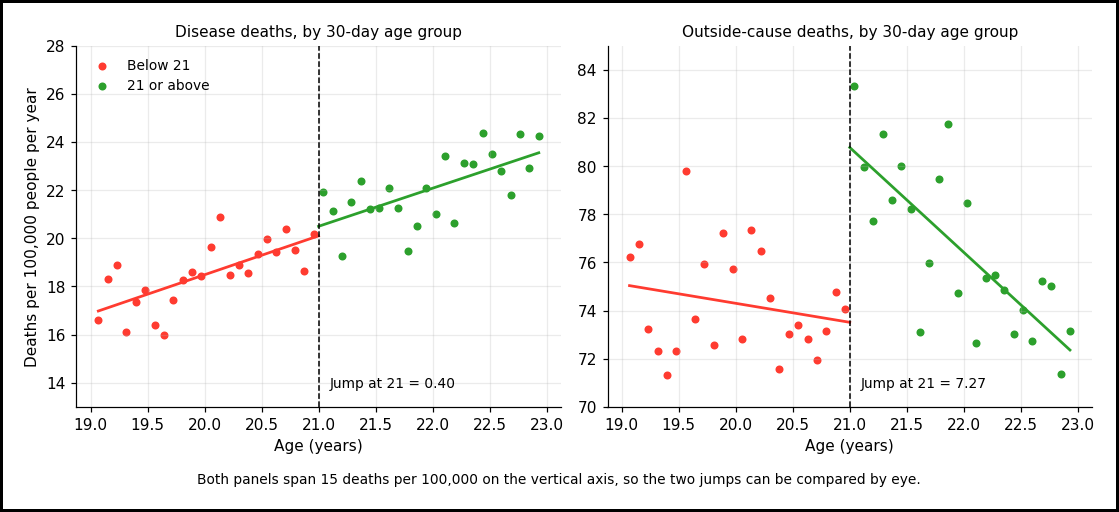

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, column, title, bottom in [(axes[0], "disease", "Disease deaths", 13), (axes[1], "outside", "Outside-cause deaths", 70)]:
    for side, color, label in [(deaths.age < 21, "#ff3b30", "Below 21"), (deaths.age >= 21, "#2ca02c", "21 or above")]:
        groups = deaths[side]
        line = fit_line(groups, column, 21)
        ends = [groups.age.min(), 21] if groups.age.max() < 21 else [21, groups.age.max()]
        ax.scatter(groups.age, groups[column], color=color, s=18, label=label)
        ax.plot(ends, [line["mean_rate"] + line["slope"] * (end - line["mean_age"]) for end in ends], color=color, lw=1.8)
    ax.axvline(21, color="black", ls="--", lw=1)
    ax.set_ylim(bottom, bottom + 15)
    ax.text(21.1, bottom + 0.8, f"Jump at 21 = {cause_jumps[column]:.2f}", fontsize=9)
    ax.set_title(f"{title}, by 30-day age group", fontsize=10)
    ax.set_xlabel("Age (years)")
axes[0].set_ylabel("Deaths per 100,000 people per year")
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
fig.text(0.5, -0.03, "Both panels span 15 deaths per 100,000 on the vertical axis, so the two jumps can be compared by eye.", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Observation:** disease deaths jump by 0.40, and 0 is inside the interval, as we want. Outside-cause deaths jump by 7.27, and 0 is outside the interval, as we want. Outside-cause deaths make up 94.9% of the jump of 7.66. If something else that changes at 21 also raised outside-cause deaths, Check 2 would show the same result, and the data can't rule out such a change.

**Conclusion:** the jump at 21 comes from the deaths that alcohol can cause within hours.

The answer to the module's question: being allowed to buy alcohol probably raises the death rate of young Americans at 21, mostly through deaths from outside causes such as accidents and suicide.

## Exercise — the jump at 21 in motor vehicle deaths

The file also splits outside-cause deaths into kinds. One kind is motor vehicle deaths: deaths in motor vehicle accidents per 100,000 people per year (column `mva`). The 2009 study found motor vehicle accidents to be the main source of the jump at 21, and the exercise measures how big that part is. Use a bandwidth of 2 years, the bandwidth of the module's main calculation. The appendix ends with the two tables for motor vehicle deaths, so every sum below can be checked.

Write your answers first, then read the answers below.

### Questions

1. What is the jump at 21 in motor vehicle deaths? This is the calculation of the section "How big is the jump at 21?", with motor vehicle deaths in place of all causes.
2. What is the jump's 95% confidence interval? Is 0 outside the interval? This is the calculation of the section "Could chance alone produce a jump of 7.66?".
3. What share of the jump in deaths from all causes, 7.66, comes from motor vehicle deaths? This is the share calculation of Check 2 in the section "Is anything other than alcohol behind the jump?".

### Answers

Every sum below comes from the two tables in the appendix section "Exercise, motor vehicle deaths, bandwidth 2 years".

**Answer 1.**

- Line below 21, motor vehicle deaths (24 age groups):
    - Mean age = (sum of ages) ÷ 24 = 480.329 ÷ 24 = 20.014 years
    - Mean death rate = (sum of death rates) ÷ 24 = 779.09 ÷ 24 = 32.46
    - Mean of (age gap × death-rate gap) = (sum of the column) ÷ 24 = (−19.95431) ÷ 24 = (−0.83143)
    - Mean of (age gap²) = (sum of the column) ÷ 24 = 7.77077 ÷ 24 = 0.32378
    - Slope = [mean of (age gap × death-rate gap)] ÷ [mean of (age gap²)] = (−0.83143) ÷ 0.32378 = (−2.568) per year of age
    - Line's death rate at 21 = (mean death rate) + [slope × (21 − mean age)] = 32.46 + [(−2.568) × (21 − 20.014)] = 29.93
- Line at 21 or above, motor vehicle deaths (24 age groups):
    - Mean age = (sum of ages) ÷ 24 = 527.671 ÷ 24 = 21.986 years
    - Mean death rate = (sum of death rates) ÷ 24 = 738.84 ÷ 24 = 30.78
    - Mean of (age gap × death-rate gap) = (sum of the column) ÷ 24 = (−28.98257) ÷ 24 = (−1.20761)
    - Mean of (age gap²) = (sum of the column) ÷ 24 = 7.77077 ÷ 24 = 0.32378
    - Slope = [mean of (age gap × death-rate gap)] ÷ [mean of (age gap²)] = (−1.20761) ÷ 0.32378 = (−3.730) per year of age
    - Line's death rate at 21 = (mean death rate) + [slope × (21 − mean age)] = 30.78 + [(−3.730) × (21 − 21.986)] = 34.46
- Jump at 21, motor vehicle deaths = (line at 21 or above, death rate at 21) − (line below 21, death rate at 21) = 34.46 − 29.93 = 4.53 deaths per 100,000 people per year.

**Answer 2.**

- Line below 21, motor vehicle deaths:
    - Sum of squared errors = (sum of the Error² column) = 37.43
    - Mean squared error = (sum of squared errors) ÷ (24 age groups − 2) = 37.43 ÷ 22 = 1.701
    - Sum of squared differences in age = (sum of the Age gap² column) = 7.77077
    - Standard error of the slope = square root of [(mean squared error) ÷ (sum of squared differences in age)] = square root of (1.701 ÷ 7.77077) = 0.468
    - Distance from the mean age to 21 = 21 − 20.014 = 0.986 years
    - Standard error of the line's death rate at 21 = square root of [(mean squared error ÷ 24) + (distance × standard error of the slope)²] = square root of [(1.701 ÷ 24) + (0.986 × 0.468)²] = 0.533
- Line at 21 or above, motor vehicle deaths:
    - Sum of squared errors = (sum of the Error² column) = 36.92
    - Mean squared error = (sum of squared errors) ÷ (24 age groups − 2) = 36.92 ÷ 22 = 1.678
    - Sum of squared differences in age = (sum of the Age gap² column) = 7.77077
    - Standard error of the slope = square root of [(mean squared error) ÷ (sum of squared differences in age)] = square root of (1.678 ÷ 7.77077) = 0.465
    - Distance from the mean age to 21 = 21.986 − 21 = 0.986 years
    - Standard error of the line's death rate at 21 = square root of [(mean squared error ÷ 24) + (distance × standard error of the slope)²] = square root of [(1.678 ÷ 24) + (0.986 × 0.465)²] = 0.529
- Standard error of the jump = square root of [(standard error, line below 21)² + (standard error, line at 21 or above)²] = square root of (0.533² + 0.529²) = 0.75
- 95% confidence interval = (jump) ± (1.96 × standard error of the jump) = 4.53 ± (1.96 × 0.75) = 3.06 to 6.00
- We want 0 outside the interval, and 0 is outside, so chance alone is an unlikely source of the jump in motor vehicle deaths.

**Answer 3.**

- Motor vehicle deaths, share of the jump at 21 = (jump, motor vehicle deaths) ÷ (jump, all causes) = 4.53 ÷ 7.66 = 59.1%

**What the answers show:** motor vehicle deaths jump by 4.53 deaths per 100,000 people per year at 21 (answer 1), with an interval of 3.06 to 6.00 that leaves out 0 (answer 2). Motor vehicle deaths make up 59.1% of the jump in deaths from all causes (answer 3), more than half of the jump.

## Interview angle

> "Orders of $50 or more get free shipping. Did free shipping make customers order again?"

A strong answer: $50 is a cutoff, so compare customers whose order was just below $50 with customers whose order was just above $50, and measure the jump at $50 in the share who ordered again. Three checks come with that jump:

- Could customers choose their side of $50? Yes: a customer at $46 can add an item to reach $50. Run the density check: count the orders in each $1 group near $50. Many more orders just above $50 than just below shows that customers chose, and customers who add items to reach free shipping may differ from customers who don't, for example by planning to order again anyway. Then the jump mixes free shipping with that difference.
- Does anything else change at $50? If a discount code also switches on at $50, the jump mixes free shipping with the discount.
- Who does the jump describe? Only customers whose orders are near $50, not customers who order $200.

## Key takeaways

- RDD measures a rule's effect as the jump between two regression lines at the cutoff: here, the death rate jumps at 21 by (line at 21 or above) − (line below 21) = 101.28 − 93.62 = 7.66 deaths per 100,000 people per year, a rise of 8.2%.
- 0 is outside the jump's interval of 5.07 to 10.25, so chance alone is an unlikely source of the jump.
- A narrower bandwidth relies less on straight lines and usually gives a wider interval. 0 stayed outside the interval at bandwidths of 2 years, 1 year and half a year.
- At fake cutoffs, 20 and 22, the method found no jump that chance can't explain.
- The jump comes from outside-cause deaths (7.27 of the 7.66), not disease deaths, which fits alcohol as the cause. Motor vehicle deaths alone make up 59.1% of the jump.
- The no-other-change rule can't be proved: another change at 21 that raises outside-cause deaths would fit the same checks.
- Being allowed to buy alcohol probably raises the death rate of young Americans at 21.

## Appendix: every line's full table

Each section after "Could chance alone produce a jump of 7.66?" prints only each line's death rate at the cutoff and the standard error of that death rate. Here is every one of those lines in full, in the order the sections use them, with the same steps as the sections "How big is the jump at 21?" and "Could chance alone produce a jump of 7.66?". A line that a section already used, for the same ages and the same deaths, is not repeated: the line's table is the same, and only the age the line is read at changes. The appendix ends with the two lines of the exercise.

In [22]:
def print_full(line, error, label):
    print_fit(line, label, list(line["table"].columns))
    print(f"  Sum of errors = {line['sum_error']:.2f}" + (", not exactly 0, because the mean death rate, the slope and each error are rounded" if round(line['sum_error'], 2) != 0 else ""))
    print(f"  Sum of squared errors = (sum of the Error² column) = {line['sum_squared']:.2f}")
    print()
    print_error(line, error, label)

seen = {}
mva_sides = []
for groups, side_label in [(deaths[deaths.age < 21], "Line below 21"), (deaths[deaths.age >= 21], "Line at 21 or above")]:
    line = fit_line(groups, "mva", 21)
    mva_sides.append((side_label, line, line_error(line)))
APPENDIX_SIDES = dict(APPENDIX + [("Exercise, motor vehicle deaths, bandwidth 2 years", mva_sides)])

def print_appendix(label, side=None):
    if side is None:
        print(f"=== {label} ===")
        print()
    for side_label, line, error in APPENDIX_SIDES[label] if side is None else [APPENDIX_SIDES[label][side]]:
        key = tuple(line["table"]["Age"]) + tuple(line["table"]["Death rate"])
        if key in seen:
            print(f"{side_label}: same {line['groups']} age groups and deaths as \"{seen[key]}\", read at {line['cutoff']} instead.")
            print()
            continue
        seen[key] = f"{label}, {side_label.lower()}"
        print_full(line, error, f"{label}, {side_label[0].lower() + side_label[1:]}")

**1 of 7:** The lines of the 1-year bandwidth, from the section "Does the jump depend on how far from 21 the lines reach?".

In [23]:
print_appendix("Bandwidth 1 year, all causes", side=0)

Bandwidth 1 year, all causes, line below 21 (12 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error   Error²
20.055       92.46   -0.452           -0.86                   0.38872   0.20430              94.05  -1.59   2.5281
20.137       98.25   -0.370            4.93                  -1.82410   0.13690              93.92   4.33  18.7489
20.219       94.96   -0.288            1.64                  -0.47232   0.08294              93.78   1.18   1.3924
20.301       93.39   -0.206            0.07                  -0.01442   0.04244              93.65  -0.26   0.0676
20.384       90.12   -0.123           -3.20                   0.39360   0.01513              93.52  -3.40  11.5600
20.466       92.41   -0.041           -0.91                   0.03731   0.00168              93.39  -0.98   0.9604
20.548       93.35    0.041            0.03                   0.00123   0.00168              93.25   0.10   0.0100
20.630       92.23 

In [24]:
print_appendix("Bandwidth 1 year, all causes", side=1)

Bandwidth 1 year, all causes, line at 21 or above (12 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error   Error²
21.041      105.27   -0.452            5.41                  -2.44532   0.20430             102.08   3.19  10.1761
21.123      101.07   -0.370            1.21                  -0.44770   0.13690             101.67  -0.60   0.3600
21.205       96.97   -0.288           -2.89                   0.83232   0.08294             101.27  -4.30  18.4900
21.288      102.83   -0.205            2.97                  -0.60885   0.04202             100.86   1.97   3.8809
21.370      100.98   -0.123            1.12                  -0.13776   0.01513             100.46   0.52   0.2704
21.452      101.24   -0.041            1.38                  -0.05658   0.00168             100.06   1.18   1.3924
21.534       99.50    0.041           -0.36                  -0.01476   0.00168              99.66  -0.16   0.0256
21.616       

**2 of 7:** The lines of the half-year bandwidth, from the section "Does the jump depend on how far from 21 the lines reach?".

In [25]:
print_appendix("Bandwidth half a year, all causes", side=0)

Bandwidth half a year, all causes, line below 21 (6 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error  Error²
20.548       93.35   -0.206            0.31                  -0.06386   0.04244              92.44   0.91  0.8281
20.630       92.23   -0.124           -0.81                   0.10044   0.01538              92.68  -0.45  0.2025
20.712       92.33   -0.042           -0.71                   0.02982   0.00176              92.92  -0.59  0.3481
20.795       92.67    0.041           -0.37                  -0.01517   0.00168              93.16  -0.49  0.2401
20.877       93.39    0.123            0.35                   0.04305   0.01513              93.40  -0.01  0.0001
20.959       94.27    0.205            1.23                   0.25215   0.04202              93.64   0.63  0.3969
  Mean age = (sum of ages) / 6 = 124.521 / 6 = 20.754 years
  Mean death rate = (sum of death rates) / 6 = 558.24 / 6 = 93.04
  Mean of (

In [26]:
print_appendix("Bandwidth half a year, all causes", side=1)

Bandwidth half a year, all causes, line at 21 or above (6 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error   Error²
21.041      105.27   -0.205            3.88                  -0.79540   0.04202             102.42   2.85   8.1225
21.123      101.07   -0.123           -0.32                   0.03936   0.01513             102.01  -0.94   0.8836
21.205       96.97   -0.041           -4.42                   0.18122   0.00168             101.60  -4.63  21.4369
21.288      102.83    0.042            1.44                   0.06048   0.00176             101.18   1.65   2.7225
21.370      100.98    0.124           -0.41                  -0.05084   0.01538             100.77   0.21   0.0441
21.452      101.24    0.206           -0.15                  -0.03090   0.04244             100.35   0.89   0.7921
  Mean age = (sum of ages) / 6 = 127.479 / 6 = 21.246 years
  Mean death rate = (sum of death rates) / 6 = 608.36 / 6 = 101.

**3 of 7:** The lines of the fake cutoff at 20, from the section "Does the method find jumps where no rule changes?".

In [27]:
print_appendix("Fake cutoff at 20, bandwidth 1 year, all causes")

=== Fake cutoff at 20, bandwidth 1 year, all causes ===

Fake cutoff at 20, bandwidth 1 year, all causes, line below 20 (12 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error   Error²
19.068       92.83   -0.452            0.54                  -0.24408   0.20430              91.41   1.42   2.0164
19.151       95.10   -0.369            2.81                  -1.03689   0.13616              91.57   3.53  12.4609
19.233       92.14   -0.287           -0.15                   0.04305   0.08237              91.73   0.41   0.1681
19.315       88.43   -0.205           -3.86                   0.79130   0.04202              91.89  -3.46  11.9716
19.397       88.70   -0.123           -3.59                   0.44157   0.01513              92.05  -3.35  11.2225
19.479       90.19   -0.041           -2.10                   0.08610   0.00168              92.21  -2.02   4.0804
19.562       96.22    0.042            3.93               

**4 of 7:** The lines of the fake cutoff at 22, from the section "Does the method find jumps where no rule changes?".

In [28]:
print_appendix("Fake cutoff at 22, bandwidth 1 year, all causes")

=== Fake cutoff at 22, bandwidth 1 year, all causes ===

Line below 22: same 12 age groups and deaths as "Bandwidth 1 year, all causes, line at 21 or above", read at 22 instead.

Fake cutoff at 22, bandwidth 1 year, all causes, line at 22 or above (12 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error  Error²
22.027       99.50   -0.453            2.28                  -1.03284   0.20521              97.80   1.70  2.8900
22.110       96.07   -0.370           -1.15                   0.42550   0.13690              97.69  -1.62  2.6244
22.192       95.97   -0.288           -1.25                   0.36000   0.08294              97.59  -1.62  2.6244
22.274       98.61   -0.206            1.39                  -0.28634   0.04244              97.48   1.13  1.2769
22.356       97.95   -0.124            0.73                  -0.09052   0.01538              97.38   0.57  0.3249
22.438       97.41   -0.042            0.19        

**5 of 7:** The lines of disease deaths, from Check 2 in the section "Is anything other than alcohol behind the jump?".

In [29]:
print_appendix("Disease deaths, bandwidth 2 years", side=0)

Disease deaths, bandwidth 2 years, line below 21 (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error  Error²
19.068       16.62   -0.946           -1.89                   1.78794   0.89492              16.98  -0.36  0.1296
19.151       18.33   -0.863           -0.18                   0.15534   0.74477              17.11   1.22  1.4884
19.233       18.91   -0.781            0.40                  -0.31240   0.60996              17.25   1.66  2.7556
19.315       16.10   -0.699           -2.41                   1.68459   0.48860              17.38  -1.28  1.6384
19.397       17.36   -0.617           -1.15                   0.70955   0.38069              17.51  -0.15  0.0225
19.479       17.87   -0.535           -0.64                   0.34240   0.28622              17.64   0.23  0.0529
19.562       16.41   -0.452           -2.10                   0.94920   0.20430              17.78  -1.37  1.8769
19.644       15.98   -

In [30]:
print_appendix("Disease deaths, bandwidth 2 years", side=1)

Disease deaths, bandwidth 2 years, line at 21 or above (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error  Error²
21.041       21.94   -0.945           -0.12                   0.11340   0.89302              20.57   1.37  1.8769
21.123       21.12   -0.863           -0.94                   0.81122   0.74477              20.69   0.43  0.1849
21.205       19.25   -0.781           -2.81                   2.19461   0.60996              20.82  -1.57  2.4649
21.288       21.51   -0.698           -0.55                   0.38390   0.48720              20.96   0.55  0.3025
21.370       22.37   -0.616            0.31                  -0.19096   0.37946              21.09   1.28  1.6384
21.452       21.23   -0.534           -0.83                   0.44322   0.28516              21.22   0.01  0.0001
21.534       21.27   -0.452           -0.79                   0.35708   0.20430              21.34  -0.07  0.0049
21.616       22.

**6 of 7:** The lines of outside-cause deaths, from Check 2 in the section "Is anything other than alcohol behind the jump?".

In [31]:
print_appendix("Outside-cause deaths, bandwidth 2 years", side=0)

Outside-cause deaths, bandwidth 2 years, line below 21 (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error   Error²
19.068       76.21   -0.946            1.92                  -1.81632   0.89492              75.04   1.17   1.3689
19.151       76.77   -0.863            2.48                  -2.14024   0.74477              74.97   1.80   3.2400
19.233       73.23   -0.781           -1.06                   0.82786   0.60996              74.91  -1.68   2.8224
19.315       72.33   -0.699           -1.96                   1.37004   0.48860              74.84  -2.51   6.3001
19.397       71.34   -0.617           -2.95                   1.82015   0.38069              74.78  -3.44  11.8336
19.479       72.32   -0.535           -1.97                   1.05395   0.28622              74.71  -2.39   5.7121
19.562       79.81   -0.452            5.52                  -2.49504   0.20430              74.65   5.16  26.6256
19.644  

In [32]:
print_appendix("Outside-cause deaths, bandwidth 2 years", side=1)

Outside-cause deaths, bandwidth 2 years, line at 21 or above (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error   Error²
21.041       83.33   -0.945            6.85                  -6.47325   0.89302              80.60   2.73   7.4529
21.123       79.94   -0.863            3.46                  -2.98598   0.74477              80.24  -0.30   0.0900
21.205       77.71   -0.781            1.23                  -0.96063   0.60996              79.88  -2.17   4.7089
21.288       81.32   -0.698            4.84                  -3.37832   0.48720              79.52   1.80   3.2400
21.370       78.61   -0.616            2.13                  -1.31208   0.37946              79.16  -0.55   0.3025
21.452       80.00   -0.534            3.52                  -1.87968   0.28516              78.81   1.19   1.4161
21.534       78.23   -0.452            1.75                  -0.79100   0.20430              78.45  -0.22   0.0484
21

**7 of 7:** The lines of motor vehicle deaths, from the section "Exercise".

In [33]:
print_appendix("Exercise, motor vehicle deaths, bandwidth 2 years", side=0)

Exercise, motor vehicle deaths, bandwidth 2 years, line below 21 (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error  Error²
19.068       35.83   -0.946            3.37                  -3.18802   0.89492              34.89   0.94  0.8836
19.151       35.64   -0.863            3.18                  -2.74434   0.74477              34.68   0.96  0.9216
19.233       34.21   -0.781            1.75                  -1.36675   0.60996              34.47  -0.26  0.0676
19.315       32.28   -0.699           -0.18                   0.12582   0.48860              34.26  -1.98  3.9204
19.397       32.65   -0.617            0.19                  -0.11723   0.38069              34.04  -1.39  1.9321
19.479       32.72   -0.535            0.26                  -0.13910   0.28622              33.83  -1.11  1.2321
19.562       36.39   -0.452            3.93                  -1.77636   0.20430              33.62   2.77  7.6729
19.644

In [34]:
print_appendix("Exercise, motor vehicle deaths, bandwidth 2 years", side=1)

Exercise, motor vehicle deaths, bandwidth 2 years, line at 21 or above (24 age groups):
   Age  Death rate  Age gap  Death-rate gap  Age gap x death-rate gap  Age gap²  Line's death rate  Error   Error²
21.041       36.32   -0.945            5.54                  -5.23530   0.89302              34.30   2.02   4.0804
21.123       32.58   -0.863            1.80                  -1.55340   0.74477              34.00  -1.42   2.0164
21.205       33.02   -0.781            2.24                  -1.74944   0.60996              33.69  -0.67   0.4489
21.288       35.11   -0.698            4.33                  -3.02234   0.48720              33.38   1.73   2.9929
21.370       32.36   -0.616            1.58                  -0.97328   0.37946              33.08  -0.72   0.5184
21.452       32.46   -0.534            1.68                  -0.89712   0.28516              32.77  -0.31   0.0961
21.534       31.53   -0.452            0.75                  -0.33900   0.20430              32.47  -0.94  